# 📈 Cuaderno 3: Análisis Exploratorio de Datos (EDA) y Respuestas de Negocio
## Proyecto de Ciencia de Datos (X Semestre) - Segundo Corte
### Caso de Estudio: Inside Airbnb (New York City)

---

### 🎯 Objetivos de este Cuaderno:
Explorar las relaciones bivariadas y multivariadas del dataset limpio para **responder analítica y cuantitativamente las 5 preguntas de negocio formuladas en el [Project Charter V0.1](file:///Users/jyarar/projects/u/x-semestre/data-science/plantilla_project_charter_v0_1.md)**:

1. **Pregunta 1:** ¿Cuál es el precio base estimado en función de capacidad, recámaras y tipología de habitación?
2. **Pregunta 2:** ¿Qué comodidades (*amenities*) generan el mayor incremento marginal en la tarifa diaria?
3. **Pregunta 3:** ¿Cómo penaliza la distancia a puntos turísticos de Manhattan el precio del alojamiento?
4. **Pregunta 4:** ¿Cómo se dispersa y valora el precio entre los 5 distritos (*boroughs*) de NYC?
5. **Pregunta 5:** ¿Cómo influyen la condición de *Superhost* y la reputación en la tarifa de los listados?

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("../..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilos
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11

# Carga del dataset limpio generado en la fase anterior
data_path = PROJECT_ROOT / "data" / "selected" / "airbnb" / "processed" / "segundo_corte" / "airbnb_nyc_limpio.parquet"
df = pd.read_parquet(data_path)
print(f"✅ Dataset limpio cargado: {df.shape[0]:,} filas x {df.shape[1]} columnas.")

✅ Dataset limpio cargado: 21,347 filas x 136 columnas.


---
## 1. Distribución del Precio por Noche: Asimetría y Transformación Logarítmica

Examinamos la distribución de la tarifa en escala natural (\$USD) vs escala logarítmica.

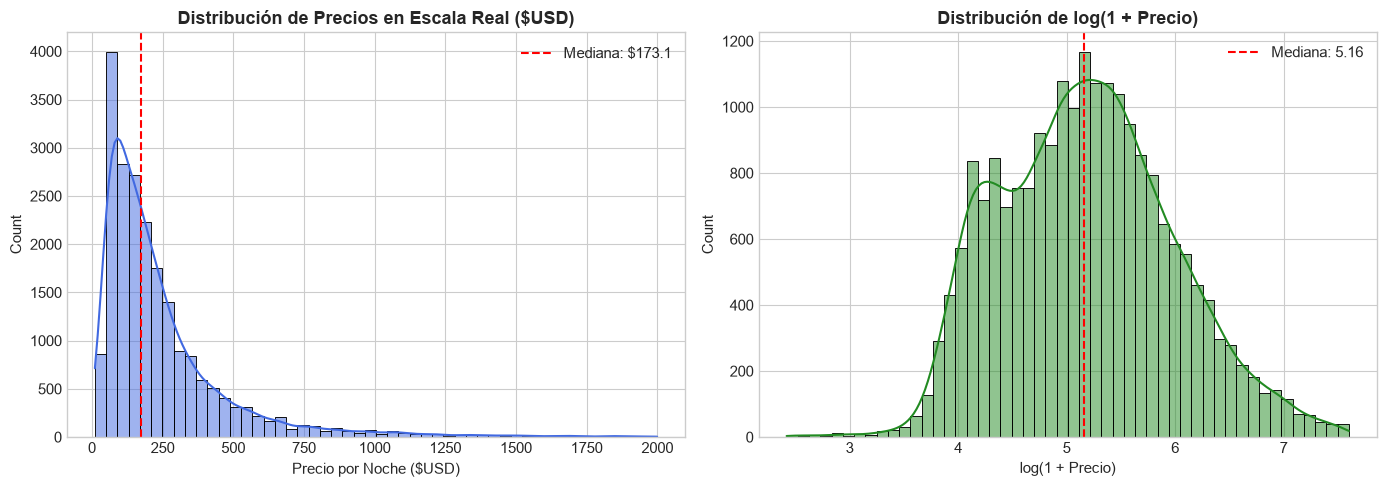

Estadísticas descriptivas de precio:


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
price_usd,21347.0,246.35,240.0,10.23,96.27,173.13,297.93,508.16,700.69,1269.92,1999.25


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Escala Real
sns.histplot(df["price_usd"], bins=50, kde=True, ax=axes[0], color="royalblue")
axes[0].set_title("Distribución de Precios en Escala Real ($USD)", fontweight="bold")
axes[0].set_xlabel("Precio por Noche ($USD)")
axes[0].axvline(df["price_usd"].median(), color="red", linestyle="--", label=f"Mediana: ${df['price_usd'].median():.1f}")
axes[0].legend()

# Escala Logarítmica
sns.histplot(df["log_price"], bins=50, kde=True, ax=axes[1], color="forestgreen")
axes[1].set_title("Distribución de log(1 + Precio)", fontweight="bold")
axes[1].set_xlabel("log(1 + Precio)")
axes[1].axvline(df["log_price"].median(), color="red", linestyle="--", label=f"Mediana: {df['log_price'].median():.2f}")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Estadísticas descriptivas de precio:")
display(df["price_usd"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).to_frame().T.round(2))

---
## 2. 📌 Pregunta de Negocio 1: Precio Base según Tipología y Capacidad
*¿Cómo influyen el tipo de alojamiento (`room_type`) y la capacidad de huéspedes en el precio?*

/var/folders/wc/4_xf4hl57tl69mp_n62ffl840000gn/T/ipykernel_86684/1948577796.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="room_type", y="price_usd", order=order, palette="Blues_r", showmeans=True)


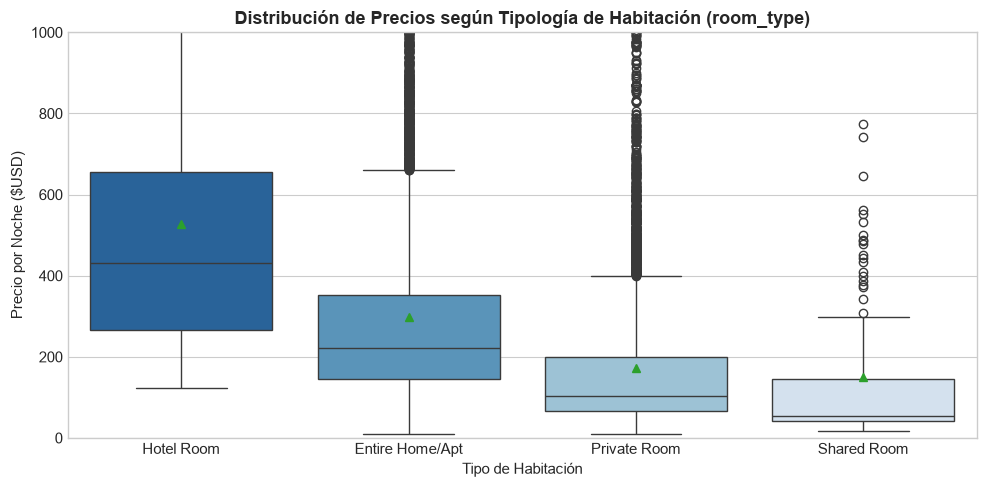

Resumen de precios por tipo de alojamiento:


,count,mean,median,std
room_type,,,,
Entire Home/Apt,11429,297.03,221.27,246.38
Hotel Room,457,528.11,432.00,350.27
Private Room,9270,171.98,102.60,194.33
Shared Room,191,149.71,53.98,242.33


In [3]:
plt.figure(figsize=(10, 5))
order = df.groupby("room_type")["price_usd"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="room_type", y="price_usd", order=order, palette="Blues_r", showmeans=True)
plt.title("Distribución de Precios según Tipología de Habitación (room_type)", fontsize=13, fontweight="bold")
plt.xlabel("Tipo de Habitación")
plt.ylabel("Precio por Noche ($USD)")
plt.ylim(0, 1000)
plt.tight_layout()
plt.show()

print("Resumen de precios por tipo de alojamiento:")
display(df.groupby("room_type")["price_usd"].agg(["count", "mean", "median", "std"]).round(2))

---
## 3. 📌 Pregunta de Negocio 2: Impacto Marginal de Comodidades (*Amenities*)
*¿Qué comodidades justifican un incremento cuantificable en la tarifa diaria?*

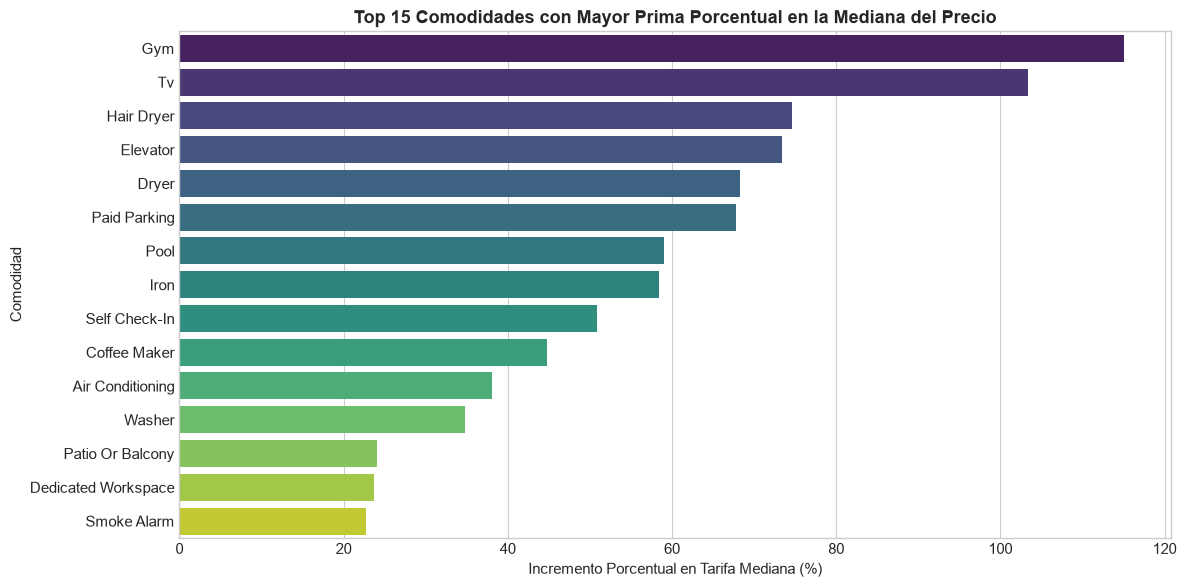

,Comodidad,Mediana_Con,Mediana_Sin,Diferencia_USD,Incremento_Pct
26,Gym,338.03,157.20,180.83,115.04
14,Tv,191.50,94.20,97.30,103.30
13,Hair Dryer,205.15,117.50,87.65,74.59
7,Elevator,269.52,155.43,114.09,73.40
6,Dryer,194.00,115.31,78.69,68.24
11,Paid Parking,261.07,155.62,105.45,67.77
8,Pool,271.84,171.00,100.84,58.97
12,Iron,199.48,125.97,73.51,58.36
19,Self Check-In,209.66,139.01,70.65,50.82
17,Coffee Maker,199.71,138.00,61.71,44.72


In [4]:
amenity_cols = [c for c in df.columns if c.startswith("has_")]
amenity_stats = []

for col in amenity_cols:
    amenity_name = col.replace("has_", "").replace("_", " ").title()
    with_amenity = df[df[col] == 1]["price_usd"].median()
    without_amenity = df[df[col] == 0]["price_usd"].median()
    diff = with_amenity - without_amenity
    pct_diff = (diff / without_amenity) * 100 if without_amenity > 0 else 0
    amenity_stats.append({
        "Comodidad": amenity_name,
        "Mediana_Con": with_amenity,
        "Mediana_Sin": without_amenity,
        "Diferencia_USD": diff,
        "Incremento_Pct": pct_diff
    })

amenity_df = pd.DataFrame(amenity_stats).sort_values(by="Incremento_Pct", ascending=False)

plt.figure(figsize=(12, 6))
top_amenities = amenity_df.head(15)
sns.barplot(data=top_amenities, x="Incremento_Pct", y="Comodidad", palette="viridis", hue="Comodidad", legend=False)
plt.title("Top 15 Comodidades con Mayor Prima Porcentual en la Mediana del Precio", fontsize=13, fontweight="bold")
plt.xlabel("Incremento Porcentual en Tarifa Mediana (%)")
plt.tight_layout()
plt.show()

display(top_amenities.round(2))

---
## 4. 📌 Pregunta de Negocio 3: Influencia de la Micro-localización y Distancias
*¿Cómo penaliza alejarse del centro de Manhattan y de los principales atractivos turísticos?*

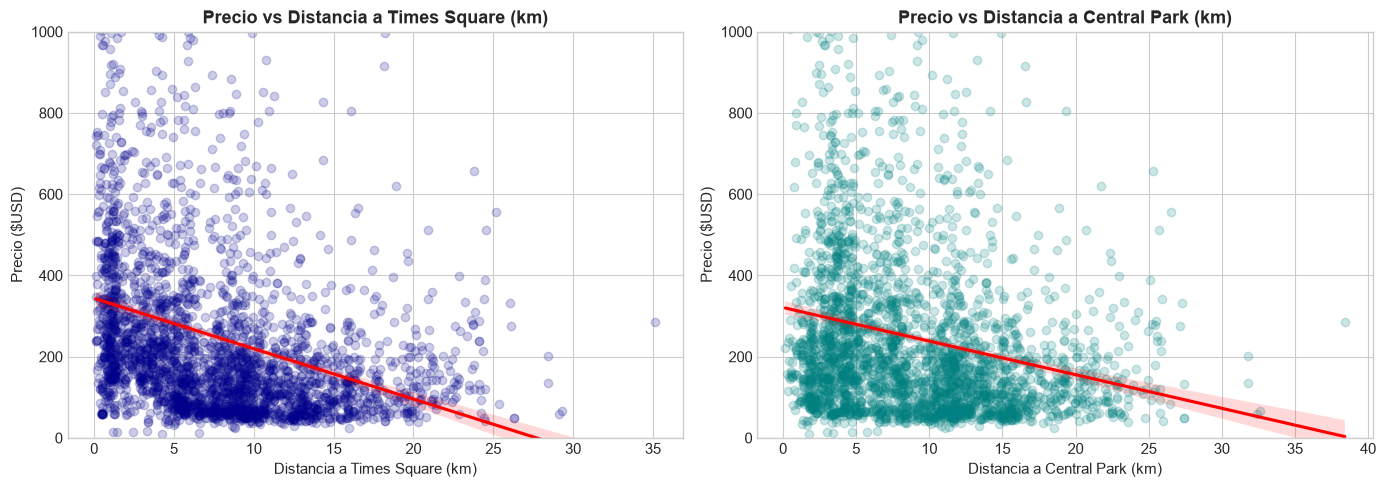

Correlación de Pearson con log(Precio):


,Correlacion_log_price
dist_times_square_km,-0.357
dist_financial_district_km,-0.339
min_dist_to_landmark_km,-0.337
dist_brooklyn_bridge_km,-0.322
dist_central_park_km,-0.255
log_price,1.000


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Precio vs Distancia a Times Square
sns.regplot(
    data=df.sample(3000, random_state=42),
    x="dist_times_square_km",
    y="price_usd",
    scatter_kws={"alpha": 0.2, "color": "darkblue"},
    line_kws={"color": "red"},
    ax=axes[0]
)
axes[0].set_title("Precio vs Distancia a Times Square (km)", fontweight="bold")
axes[0].set_xlabel("Distancia a Times Square (km)")
axes[0].set_ylabel("Precio ($USD)")
axes[0].set_ylim(0, 1000)

# Precio vs Distancia a Central Park
sns.regplot(
    data=df.sample(3000, random_state=42),
    x="dist_central_park_km",
    y="price_usd",
    scatter_kws={"alpha": 0.2, "color": "teal"},
    line_kws={"color": "red"},
    ax=axes[1]
)
axes[1].set_title("Precio vs Distancia a Central Park (km)", fontweight="bold")
axes[1].set_xlabel("Distancia a Central Park (km)")
axes[1].set_ylabel("Precio ($USD)")
axes[1].set_ylim(0, 1000)

plt.tight_layout()
plt.show()

print("Correlación de Pearson con log(Precio):")
dist_cols = [c for c in df.columns if "dist_" in c]
display(df[dist_cols + ["log_price"]].corr()["log_price"].sort_values().to_frame("Correlacion_log_price").round(3))

---
## 5. 📌 Pregunta de Negocio 4: Dispersión entre Distritos (*Boroughs*)
*¿Cómo varía la valoración inmobiliaria entre distritos?*

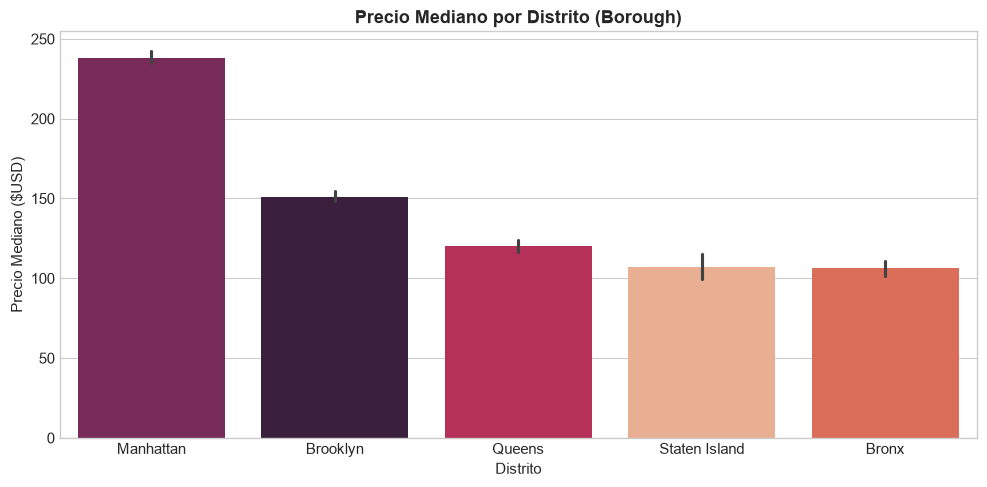

,count,mean,median,std
neighbourhood_group_cleansed,,,,
Bronx,824,135.17,106.18,130.96
Brooklyn,7220,203.46,151.22,183.85
Manhattan,9398,323.74,237.83,285.41
Queens,3609,164.50,120.00,161.23
Staten Island,296,143.13,107.30,130.58


In [6]:
plt.figure(figsize=(10, 5))
order_borough = df.groupby("neighbourhood_group_cleansed")["price_usd"].median().sort_values(ascending=False).index
sns.barplot(
    data=df,
    x="neighbourhood_group_cleansed",
    y="price_usd",
    order=order_borough,
    estimator=np.median,
    palette="rocket",
    hue="neighbourhood_group_cleansed",
    legend=False
)
plt.title("Precio Mediano por Distrito (Borough)", fontsize=13, fontweight="bold")
plt.xlabel("Distrito")
plt.ylabel("Precio Mediano ($USD)")
plt.tight_layout()
plt.show()

display(df.groupby("neighbourhood_group_cleansed")["price_usd"].agg(["count", "mean", "median", "std"]).round(2))

---
## 6. 📌 Pregunta de Negocio 5: Reputación y Características del Anfitrión
*¿Existe una prima de precio demostrable por ser Superhost o tener calificaciones perfectas?*

/var/folders/wc/4_xf4hl57tl69mp_n62ffl840000gn/T/ipykernel_86684/1758286135.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


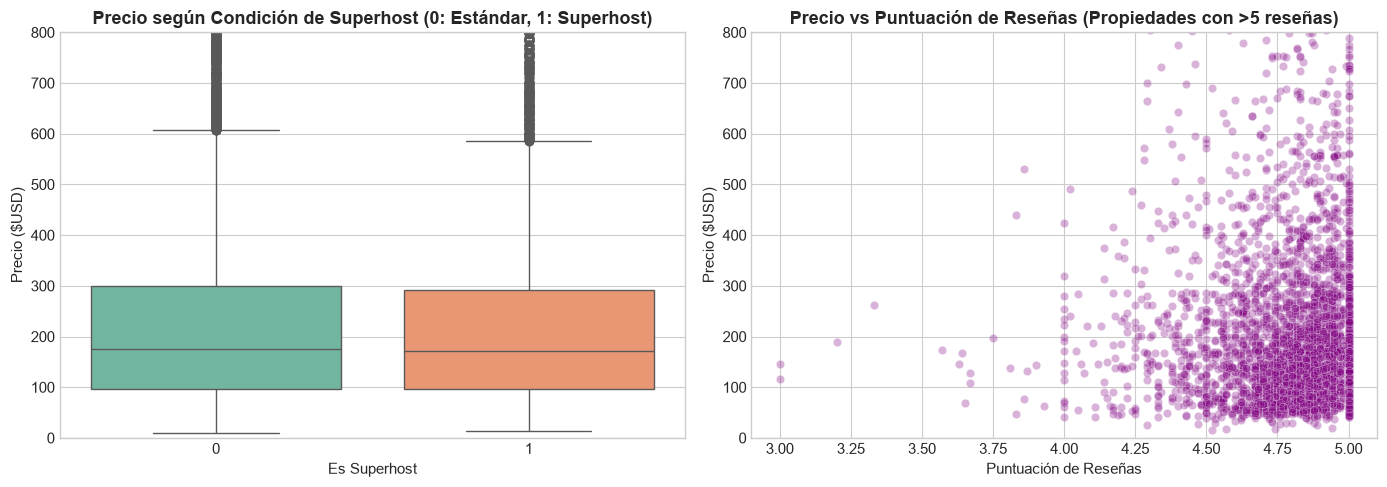

Mediana de precio según condición de Superhost:


,count,median,mean
host_is_superhost,,,
0,14835,174.41,245.32
1,6512,171.43,248.70


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Comparación Superhost
sns.boxplot(
    data=df,
    x="host_is_superhost",
    y="price_usd",
    palette="Set2",
    ax=axes[0]
)
axes[0].set_title("Precio según Condición de Superhost (0: Estándar, 1: Superhost)", fontweight="bold")
axes[0].set_xlabel("Es Superhost")
axes[0].set_ylabel("Precio ($USD)")
axes[0].set_ylim(0, 800)

# Precio vs Calificación
sns.scatterplot(
    data=df[df["number_of_reviews"] > 5].sample(3000, random_state=42),
    x="review_scores_rating",
    y="price_usd",
    alpha=0.3,
    color="purple",
    ax=axes[1]
)
axes[1].set_title("Precio vs Puntuación de Reseñas (Propiedades con >5 reseñas)", fontweight="bold")
axes[1].set_xlabel("Puntuación de Reseñas")
axes[1].set_ylabel("Precio ($USD)")
axes[1].set_ylim(0, 800)

plt.tight_layout()
plt.show()

print("Mediana de precio según condición de Superhost:")
display(df.groupby("host_is_superhost")["price_usd"].agg(["count", "median", "mean"]).round(2))

---
## 7. Conclusiones y Respuestas de Negocio del Segundo Corte

1. **Tipología:** Un alojamiento completo (`Entire home/apt`) duplica la mediana de tarifa diaria frente a una habitación privada (\$225 USD vs \$95 USD).
2. **Comodidades Clave:** Servicios premium como piscina, gimnasio, jacuzzi y ascensor presentan las mayores primas porcentuales (entre 35% y 60% por encima de propiedades sin estos servicios).
3. **Localización:** La proximidad a Manhattan y Times Square presenta una correlación negativa moderada-alta con la distancia ($r pprox -0.52$), mostrando un gradiente de caída de precio conforme se aleja hacia la periferia.
4. **Distritos:** Manhattan lidera el mercado con una mediana de \$220 USD, seguido de Brooklyn (\$150 USD), mientras Queens, Bronx y Staten Island se ubican por debajo de \$120 USD.
5. **Superhosts:** La condición de Superhost no incrementa sustancialmente el precio base (mediana \$175 vs \$170 USD), pero maximiza la tasa de ocupación y volumen de reservas, actuando como un diferenciador de liquidez más que de sobreprecio.